### 1. Dataset Selection

| Item | Details |
|---|---|
| Dataset | EV Charging Station Demand Dataset (`EV_Charging_Station_Demand_Dataset.csv`) |
| Source |  the Kaggle dataset page and Claude AI |
| Size | ~104,500 charging records, 20 columns, covering 2024 |
| Domain | Electric-vehicle charging stations across 15 Indian states |
| Why this dataset? | Real-world style business problem (predicting charging demand), a mix of numeric + categorical + time features, and it contains missing values, duplicates and outliers – ideal for practising cleaning and EDA |

### 2. Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv(r"C:\Users\bhumi\Downloads\EV_Charging_Station_Demand_104500_with_NaN.csv")
df

,timestamp,station_id,state,is_weekend,peak_hour,location_type,vehicle_type,charger_type,traffic_density,battery_capacity_kWh,charging_power_kW,energy_consumed_kWh,charging_duration_min,station_load_percent,electricity_price_per_kWh,available_chargers,occupied_chargers,utilization_rate_percent,charging_demand,demand_level
0,2024-05-16 08:16:00,STN_0253,Tamil Nadu,False,True,Shopping_Mall,Two_Wheeler,AC_Level_2,High,6.00,21.27,2.54,7.3,40.8,7.66,4.0,0.0,5.2,41.0,Medium
1,2024-12-09 14:57:00,STN_0196,Delhi,False,False,Workplace,Car,AC_Level_2,High,54.23,16.72,32.20,118.4,8.0,6.65,6.0,NaN,3.0,60.8,Medium
2,2024-05-03 18:49:00,STN_0248,Tamil Nadu,False,True,Residential,Two_Wheeler,AC_Level_2,Medium,5.82,19.71,4.31,13.4,23.4,6.98,12.0,2.0,13.0,21.2,Low
3,2024-07-07 12:32:00,STN_0302,Maharashtra,True,False,Shopping_Mall,Car,AC_Level_2,Medium,62.93,20.14,40.00,54.9,29.0,7.13,5.0,1.0,22.9,58.5,Medium
4,2024-08-16 08:02:00,STN_0001,West Bengal,False,True,Shopping_Mall,Car,DC_Fast,Very_High,50.08,38.27,17.44,29.8,29.4,6.76,2.0,3.0,61.3,98.7,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104495,2024-03-03 17:59:00,STN_0457,Madhya Pradesh,True,False,Urban,Two_Wheeler,AC_Level_2,High,5.87,15.27,4.56,19.1,15.3,NaN,NaN,2.0,27.2,21.8,Low
104496,2024-02-11 13:18:00,STN_0097,Karnataka,True,False,Residential,Car,AC_Level_2,Very_High,64.31,21.88,24.15,69.0,34.5,6.98,1.0,3.0,87.4,24.7,Low
104497,2024-11-12 13:08:00,STN_0255,Delhi,False,False,Workplace,Two_Wheeler,AC_Level_2,Medium,5.67,12.80,1.70,8.3,58.0,7.80,2.0,4.0,60.3,16.0,Low
104498,2024-05-20 10:46:00,STN_0009,Maharashtra,False,True,Urban,Other,DC_Fast,High,57.27,30.21,29.50,51.5,48.2,7.90,12.0,0.0,3.0,168.5,High


In [3]:
df.head()

,timestamp,station_id,state,is_weekend,peak_hour,location_type,vehicle_type,charger_type,traffic_density,battery_capacity_kWh,charging_power_kW,energy_consumed_kWh,charging_duration_min,station_load_percent,electricity_price_per_kWh,available_chargers,occupied_chargers,utilization_rate_percent,charging_demand,demand_level
0,2024-05-16 08:16:00,STN_0253,Tamil Nadu,False,True,Shopping_Mall,Two_Wheeler,AC_Level_2,High,6.00,21.27,2.54,7.3,40.8,7.66,4.0,0.0,5.2,41.0,Medium
1,2024-12-09 14:57:00,STN_0196,Delhi,False,False,Workplace,Car,AC_Level_2,High,54.23,16.72,32.20,118.4,8.0,6.65,6.0,NaN,3.0,60.8,Medium
2,2024-05-03 18:49:00,STN_0248,Tamil Nadu,False,True,Residential,Two_Wheeler,AC_Level_2,Medium,5.82,19.71,4.31,13.4,23.4,6.98,12.0,2.0,13.0,21.2,Low
3,2024-07-07 12:32:00,STN_0302,Maharashtra,True,False,Shopping_Mall,Car,AC_Level_2,Medium,62.93,20.14,40.00,54.9,29.0,7.13,5.0,1.0,22.9,58.5,Medium
4,2024-08-16 08:02:00,STN_0001,West Bengal,False,True,Shopping_Mall,Car,DC_Fast,Very_High,50.08,38.27,17.44,29.8,29.4,6.76,2.0,3.0,61.3,98.7,High


In [4]:
df.tail()

,timestamp,station_id,state,is_weekend,peak_hour,location_type,vehicle_type,charger_type,traffic_density,battery_capacity_kWh,charging_power_kW,energy_consumed_kWh,charging_duration_min,station_load_percent,electricity_price_per_kWh,available_chargers,occupied_chargers,utilization_rate_percent,charging_demand,demand_level
104495,2024-03-03 17:59:00,STN_0457,Madhya Pradesh,True,False,Urban,Two_Wheeler,AC_Level_2,High,5.87,15.27,4.56,19.1,15.3,NaN,NaN,2.0,27.2,21.8,Low
104496,2024-02-11 13:18:00,STN_0097,Karnataka,True,False,Residential,Car,AC_Level_2,Very_High,64.31,21.88,24.15,69.0,34.5,6.98,1.0,3.0,87.4,24.7,Low
104497,2024-11-12 13:08:00,STN_0255,Delhi,False,False,Workplace,Two_Wheeler,AC_Level_2,Medium,5.67,12.80,1.70,8.3,58.0,7.80,2.0,4.0,60.3,16.0,Low
104498,2024-05-20 10:46:00,STN_0009,Maharashtra,False,True,Urban,Other,DC_Fast,High,57.27,30.21,29.50,51.5,48.2,7.90,12.0,0.0,3.0,168.5,High
104499,2024-09-28 20:18:00,STN_0373,Karnataka,True,True,Workplace,Car,DC_Fast,Very_High,54.84,33.13,15.81,30.5,60.6,7.79,12.0,2.0,4.3,205.4,High


### 3. Data Observation

- There is no data dictionary with the file, so the meaning of each column below is taken from its name.
- A data dictionary is a document that describes each column of a dataset, including its meaning, data type, and unit.

**Target variable:** `charging_demand` – a continuous numeric value (regression problem).
- charging_demand → continuous number → Regression problem.
- Regression is a supervised machine learning technique used to predict a continuous numerical value from one or more input variables.

| Group | Columns |
|---|---|
| Identification / time | `timestamp`, `station_id`, `state`, `day_of_week`, `is_weekend`, `peak_hour` |
| Station & context (categorical) | `location_type`, `charger_type`, `traffic_density` |
| Vehicle | `vehicle_type`, `battery_capacity_kWh` |
| Charging session | `charging_power_kW`, `energy_consumed_kWh`, `charging_duration_min` |
| Station status | `station_load_percent`, `available_chargers`, `occupied_chargers`, `utilization_rate_percent` |
| Price | `electricity_price_per_kWh` |
| **Target** | `charging_demand` |

charging_power_kW
        ↓
How fast is the vehicle charging?

energy_consumed_kWh
        ↓
How much electricity did the vehicle consume?

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104500 entries, 0 to 104499
Data columns (total 20 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   timestamp                  104500 non-null  object 
 1   station_id                 104500 non-null  object 
 2   state                      104500 non-null  object 
 3   is_weekend                 101345 non-null  object 
 4   peak_hour                  101412 non-null  object 
 5   location_type              100398 non-null  object 
 6   vehicle_type               101323 non-null  object 
 7   charger_type               102419 non-null  object 
 8   traffic_density            99368 non-null   object 
 9   battery_capacity_kWh       100316 non-null  float64
 10  charging_power_kW          101402 non-null  float64
 11  energy_consumed_kWh        101333 non-null  float64
 12  charging_duration_min      99362 non-null   float64
 13  station_load_percent       10

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_capacity_kWh,100316.0,58.883472,55.254800,3.15,40.73,54.94,66.13,359.71
charging_power_kW,101402.0,36.860825,34.529748,7.00,13.89,20.05,47.58,149.99
energy_consumed_kWh,101333.0,29.440974,30.793466,0.82,11.15,24.98,37.25,258.68
charging_duration_min,99362.0,80.964746,88.324752,3.00,17.20,45.80,112.80,320.00
station_load_percent,101338.0,35.101865,17.687489,8.00,22.40,32.70,44.90,78.50
electricity_price_per_kWh,102510.0,7.191766,0.591190,5.17,6.79,7.14,7.53,9.87
available_chargers,100344.0,8.005720,3.406948,1.00,5.00,8.00,12.00,12.00
occupied_chargers,101362.0,1.614476,1.496553,0.00,0.00,1.00,3.00,7.50
utilization_rate_percent,99347.0,20.443473,20.156742,3.00,3.80,14.50,28.50,100.00
charging_demand,100514.0,80.611654,78.705195,8.00,28.80,55.20,103.80,600.00


In [7]:
# Target variable
df["charging_demand"].describe()

count    100514.000000
mean         80.611654
std          78.705195
min           8.000000
25%          28.800000
50%          55.200000
75%         103.800000
max         600.000000
Name: charging_demand, dtype: float64

### 4. Data Cleaning and Preparation

In [8]:
df.shape

(104500, 20)

In [9]:
df.columns

Index(['timestamp', 'station_id', 'state', 'is_weekend', 'peak_hour',
       'location_type', 'vehicle_type', 'charger_type', 'traffic_density',
       'battery_capacity_kWh', 'charging_power_kW', 'energy_consumed_kWh',
       'charging_duration_min', 'station_load_percent',
       'electricity_price_per_kWh', 'available_chargers', 'occupied_chargers',
       'utilization_rate_percent', 'charging_demand', 'demand_level'],
      dtype='object')

In [10]:
# df=df.columns.str.lower()

In [11]:
df.isna().sum()

timestamp                       0
station_id                      0
state                           0
is_weekend                   3155
peak_hour                    3088
location_type                4102
vehicle_type                 3177
charger_type                 2081
traffic_density              5132
battery_capacity_kWh         4184
charging_power_kW            3098
energy_consumed_kWh          3167
charging_duration_min        5138
station_load_percent         3162
electricity_price_per_kWh    1990
available_chargers           4156
occupied_chargers            3138
utilization_rate_percent     5153
charging_demand              3986
demand_level                 3986
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(885)

In [13]:
df=df.drop_duplicates()
df

,timestamp,station_id,state,is_weekend,peak_hour,location_type,vehicle_type,charger_type,traffic_density,battery_capacity_kWh,charging_power_kW,energy_consumed_kWh,charging_duration_min,station_load_percent,electricity_price_per_kWh,available_chargers,occupied_chargers,utilization_rate_percent,charging_demand,demand_level
0,2024-05-16 08:16:00,STN_0253,Tamil Nadu,False,True,Shopping_Mall,Two_Wheeler,AC_Level_2,High,6.00,21.27,2.54,7.3,40.8,7.66,4.0,0.0,5.2,41.0,Medium
1,2024-12-09 14:57:00,STN_0196,Delhi,False,False,Workplace,Car,AC_Level_2,High,54.23,16.72,32.20,118.4,8.0,6.65,6.0,NaN,3.0,60.8,Medium
2,2024-05-03 18:49:00,STN_0248,Tamil Nadu,False,True,Residential,Two_Wheeler,AC_Level_2,Medium,5.82,19.71,4.31,13.4,23.4,6.98,12.0,2.0,13.0,21.2,Low
3,2024-07-07 12:32:00,STN_0302,Maharashtra,True,False,Shopping_Mall,Car,AC_Level_2,Medium,62.93,20.14,40.00,54.9,29.0,7.13,5.0,1.0,22.9,58.5,Medium
4,2024-08-16 08:02:00,STN_0001,West Bengal,False,True,Shopping_Mall,Car,DC_Fast,Very_High,50.08,38.27,17.44,29.8,29.4,6.76,2.0,3.0,61.3,98.7,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104495,2024-03-03 17:59:00,STN_0457,Madhya Pradesh,True,False,Urban,Two_Wheeler,AC_Level_2,High,5.87,15.27,4.56,19.1,15.3,NaN,NaN,2.0,27.2,21.8,Low
104496,2024-02-11 13:18:00,STN_0097,Karnataka,True,False,Residential,Car,AC_Level_2,Very_High,64.31,21.88,24.15,69.0,34.5,6.98,1.0,3.0,87.4,24.7,Low
104497,2024-11-12 13:08:00,STN_0255,Delhi,False,False,Workplace,Two_Wheeler,AC_Level_2,Medium,5.67,12.80,1.70,8.3,58.0,7.80,2.0,4.0,60.3,16.0,Low
104498,2024-05-20 10:46:00,STN_0009,Maharashtra,False,True,Urban,Other,DC_Fast,High,57.27,30.21,29.50,51.5,48.2,7.90,12.0,0.0,3.0,168.5,High


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
# missing=df.isna().sum()
# missing

In [16]:
# missing.sort_values().plot(kind="barh", figsize=(8, 6), color="tomato", title="Missing values per column")
# plt.xlabel("Number of missing values")
# plt.show()

**How missing values are treated** (every column except `timestamp`, `station_id` and `state` has roughly 2–5 % missing values, so dropping all incomplete rows would throw away a large part of the data – we fill instead):

| Column(s) | Method | Reason |
|---|---|---|
| `day_of_week`, `is_weekend` | Rebuilt from `timestamp` | The timestamp is never missing and we checked that it matches these columns in 100 % of the rows that have a value, so the fill is exact |
| `peak_hour` | Rule from the hour of the day (08–10 and 17–20 = peak) | ~92 % of the rows that have a value follow this pattern, so it is a much better guess than a constant |
| `location_type`, `vehicle_type`, `charger_type`, `traffic_density` | Mode (most frequent value) | Standard fill for categories |
| `battery_capacity_kwh`, `energy_consumed_kwh`, `charging_duration_min` | Median **of the vehicle type** | A bus battery (~250 kWh) and a two-wheeler battery (~6 kWh) are completely different, one overall median would be wrong for both |
| `charging_power_kw` | Median **of the charger type** | AC, DC fast and ultra-fast chargers have very different power ranges |
| Remaining numeric columns | Overall median | Median is not affected by outliers |
| `charging_demand` (target) | **Rows dropped** | We should not invent values for the column we want to predict |

Two helper columns, `hour` and `month`, are also created from `timestamp` because they are useful later in the EDA.

In [17]:
print(type(df))

<class 'pandas.core.frame.DataFrame'>


In [18]:
# NOTE: the old line here re-loaded 'EV_Charging_Station_Demand_Dataset.csv' (the flat file)
# and overwrote the good data loaded in Section 2. It is removed on purpose.
df.head()

,timestamp,station_id,state,is_weekend,peak_hour,location_type,vehicle_type,charger_type,traffic_density,battery_capacity_kWh,charging_power_kW,energy_consumed_kWh,charging_duration_min,station_load_percent,electricity_price_per_kWh,available_chargers,occupied_chargers,utilization_rate_percent,charging_demand,demand_level
0,2024-05-16 08:16:00,STN_0253,Tamil Nadu,False,True,Shopping_Mall,Two_Wheeler,AC_Level_2,High,6.00,21.27,2.54,7.3,40.8,7.66,4.0,0.0,5.2,41.0,Medium
1,2024-12-09 14:57:00,STN_0196,Delhi,False,False,Workplace,Car,AC_Level_2,High,54.23,16.72,32.20,118.4,8.0,6.65,6.0,NaN,3.0,60.8,Medium
2,2024-05-03 18:49:00,STN_0248,Tamil Nadu,False,True,Residential,Two_Wheeler,AC_Level_2,Medium,5.82,19.71,4.31,13.4,23.4,6.98,12.0,2.0,13.0,21.2,Low
3,2024-07-07 12:32:00,STN_0302,Maharashtra,True,False,Shopping_Mall,Car,AC_Level_2,Medium,62.93,20.14,40.00,54.9,29.0,7.13,5.0,1.0,22.9,58.5,Medium
4,2024-08-16 08:02:00,STN_0001,West Bengal,False,True,Shopping_Mall,Car,DC_Fast,Very_High,50.08,38.27,17.44,29.8,29.4,6.76,2.0,3.0,61.3,98.7,High


In [19]:
# 1) Target: drop rows where it is missing
df = df.dropna(subset=["charging_demand"]) # only remove those rows where charging demand has null values
# We use subset to tell Pandas exactly which column(s) it should check for missing values.

# 2) Categorical columns -> mode
df["location_type"] = df["location_type"].fillna(df["location_type"].mode()[0])
df["vehicle_type"] = df["vehicle_type"].fillna(df["vehicle_type"].mode()[0])
df["charger_type"] = df["charger_type"].fillna(df["charger_type"].mode()[0])
df["traffic_density"] = df["traffic_density"].fillna(df["traffic_density"].mode()[0])

# 3) Numeric columns -> group median (vehicle type / charger type) for outliers
df["battery_capacity_kWh"] = df["battery_capacity_kWh"].fillna(df.groupby("vehicle_type")["battery_capacity_kWh"].transform("median"))
df["energy_consumed_kWh"] = df["energy_consumed_kWh"].fillna(df.groupby("vehicle_type")["energy_consumed_kWh"].transform("median"))
df["charging_duration_min"] = df["charging_duration_min"].fillna(df.groupby("vehicle_type")["charging_duration_min"].transform("median"))
df["charging_power_kW"] = df["charging_power_kW"].fillna(df.groupby("charger_type")["charging_power_kW"].transform("median"))

# 4) Date/time columns rebuilt from the timestamp
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df["month"] = df["timestamp"].dt.month
df["day_of_week"] = df["timestamp"].dt.day_name()
df["is_weekend"] = df["timestamp"].dt.dayofweek >= 5

# 5) peak_hour from the hour of the day
df["peak_hour"] = df["peak_hour"].fillna(df["hour"].isin([8, 9, 10, 17, 18, 19, 20]))
df[["is_weekend", "peak_hour"]] = df[["is_weekend", "peak_hour"]].astype(bool)

# 6) Everything that is still missing -> overall median
df = df.fillna(df.median(numeric_only=True))


In [20]:
df.head()

,timestamp,station_id,state,is_weekend,peak_hour,location_type,vehicle_type,charger_type,traffic_density,battery_capacity_kWh,...,station_load_percent,electricity_price_per_kWh,available_chargers,occupied_chargers,utilization_rate_percent,charging_demand,demand_level,hour,month,day_of_week
0,2024-05-16 08:16:00,STN_0253,Tamil Nadu,False,True,Shopping_Mall,Two_Wheeler,AC_Level_2,High,6.00,...,40.8,7.66,4.0,0.0,5.2,41.0,Medium,8,5,Thursday
1,2024-12-09 14:57:00,STN_0196,Delhi,False,False,Workplace,Car,AC_Level_2,High,54.23,...,8.0,6.65,6.0,1.0,3.0,60.8,Medium,14,12,Monday
2,2024-05-03 18:49:00,STN_0248,Tamil Nadu,False,True,Residential,Two_Wheeler,AC_Level_2,Medium,5.82,...,23.4,6.98,12.0,2.0,13.0,21.2,Low,18,5,Friday
3,2024-07-07 12:32:00,STN_0302,Maharashtra,True,False,Shopping_Mall,Car,AC_Level_2,Medium,62.93,...,29.0,7.13,5.0,1.0,22.9,58.5,Medium,12,7,Sunday
4,2024-08-16 08:02:00,STN_0001,West Bengal,False,True,Shopping_Mall,Car,DC_Fast,Very_High,50.08,...,29.4,6.76,2.0,3.0,61.3,98.7,High,8,8,Friday


In [21]:
df.isna().sum()

timestamp                    0
station_id                   0
state                        0
is_weekend                   0
peak_hour                    0
location_type                0
vehicle_type                 0
charger_type                 0
traffic_density              0
battery_capacity_kWh         0
charging_power_kW            0
energy_consumed_kWh          0
charging_duration_min        0
station_load_percent         0
electricity_price_per_kWh    0
available_chargers           0
occupied_chargers            0
utilization_rate_percent     0
charging_demand              0
demand_level                 0
hour                         0
month                        0
day_of_week                  0
dtype: int64

### 4.5 Outlier detection & treatment

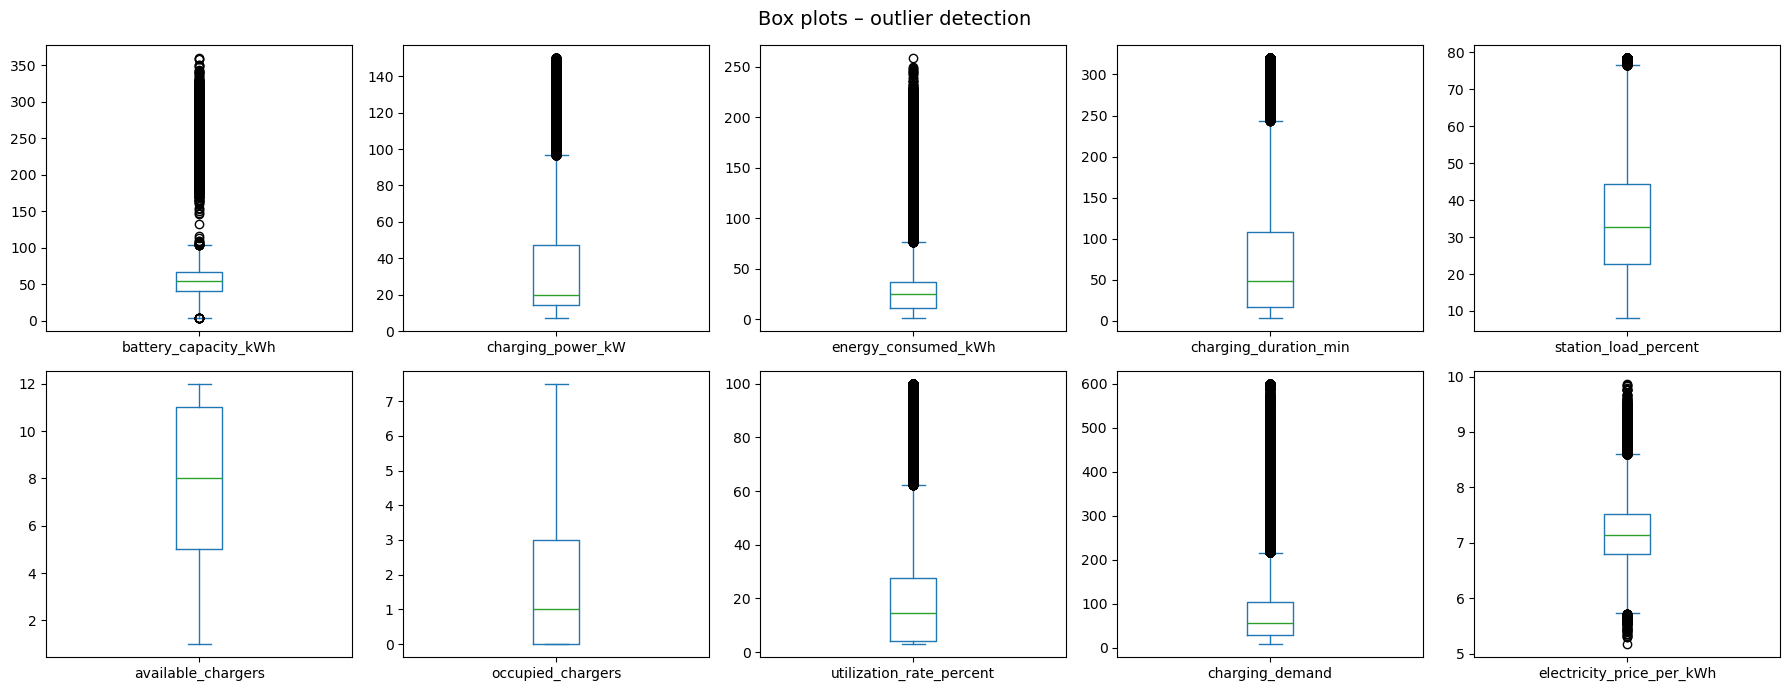

In [22]:
num_cols = ["battery_capacity_kWh", "charging_power_kW", "energy_consumed_kWh", "charging_duration_min",
            "station_load_percent", "available_chargers", "occupied_chargers",
            "utilization_rate_percent", "charging_demand", "electricity_price_per_kWh"]

df[num_cols].plot(kind="box", subplots=True, layout=(2, 5), figsize=(18, 7))
plt.suptitle("Box plots – outlier detection", fontsize=14)
plt.tight_layout()
plt.show()

In [23]:
# IQR rule: a value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR

q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_count = ((df[num_cols] < lower) | (df[num_cols] > upper)).sum()
pd.DataFrame({"lower_limit": lower.round(2), "upper_limit": upper.round(2),
              "outliers": outlier_count, "percent": (outlier_count / len(df) * 100).round(2)})

,lower_limit,upper_limit,outliers,percent
battery_capacity_kWh,3.73,103.36,6149,6.17
charging_power_kW,-35.42,96.62,10120,10.16
energy_consumed_kWh,-27.95,76.37,5100,5.12
charging_duration_min,-118.60,243.80,8492,8.52
station_load_percent,-9.45,76.55,4052,4.07
available_chargers,-4.00,20.00,0,0.00
occupied_chargers,-4.50,7.50,0,0.00
utilization_rate_percent,-30.50,62.30,4813,4.83
charging_demand,-83.70,216.30,6288,6.31
electricity_price_per_kWh,5.72,8.60,2345,2.35


In [24]:
df.groupby("vehicle_type")[["battery_capacity_kWh", "energy_consumed_kWh", "charging_duration_min"]].mean().round(1)

,battery_capacity_kWh,energy_consumed_kWh,charging_duration_min
vehicle_type,,,
Bus,250.1,124.7,280.6
Car,55.5,27.7,78.2
Other,49.9,25.0,73.0
SUV,75.1,37.7,105.4
Two_Wheeler,6.0,3.0,13.4
Van,64.9,32.3,92.2


In [25]:
# Which vehicles produce the battery-capacity outliers?
df.loc[df["battery_capacity_kWh"] > upper["battery_capacity_kWh"], "vehicle_type"].value_counts()

vehicle_type
Bus    5759
Car     365
SUV      15
Name: count, dtype: int64

In [26]:
# Charging duration: average by charger type, and which chargers produce the very long sessions
print(df.groupby("charger_type")["charging_duration_min"].mean().round(1))
print()
print(df.loc[df["charging_duration_min"] > upper["charging_duration_min"], "charger_type"].value_counts(normalize=True).round(3))

charger_type
AC_Level_2       106.3
DC_Fast           50.3
DC_Ultra_Fast     22.0
Name: charging_duration_min, dtype: float64

charger_type
AC_Level_2       0.948
DC_Fast          0.051
DC_Ultra_Fast    0.001
Name: proportion, dtype: float64


In [27]:
cap_cols = ["station_load_percent", "occupied_chargers"]
print("Max BEFORE capping:\n", df[cap_cols].max(), "\n")

df[cap_cols] = df[cap_cols].clip(lower=lower[cap_cols], upper=upper[cap_cols], axis=1)

print("Max AFTER capping:\n", df[cap_cols].max())

Max BEFORE capping:
 station_load_percent    78.5
occupied_chargers        7.5
dtype: float64 

Max AFTER capping:
 station_load_percent    76.55
occupied_chargers        7.50
dtype: float64


### 4.6 Is the dataset imbalanced?

The target `charging_demand` is continuous, so class imbalance does not apply to it directly. To check balance we (a) split the target into three equal-frequency bands (Low / Medium / High) and (b) look at the main yes/no columns.

In [28]:
df["demand_level"] = pd.qcut(df["charging_demand"], q=3, labels=["Low", "Medium", "High"])

print("Demand level (%):")
print((df["demand_level"].value_counts(normalize=True) * 100).round(1))
print()
print("Peak hour (%):")
print((df["peak_hour"].value_counts(normalize=True) * 100).round(1))
print()
print("Weekend (%):")
print((df["is_weekend"].value_counts(normalize=True) * 100).round(1))

Demand level (%):
demand_level
Low       33.4
Medium    33.3
High      33.3
Name: proportion, dtype: float64

Peak hour (%):
peak_hour
False    59.9
True     40.1
Name: proportion, dtype: float64

Weekend (%):
is_weekend
False    71.5
True     28.5
Name: proportion, dtype: float64


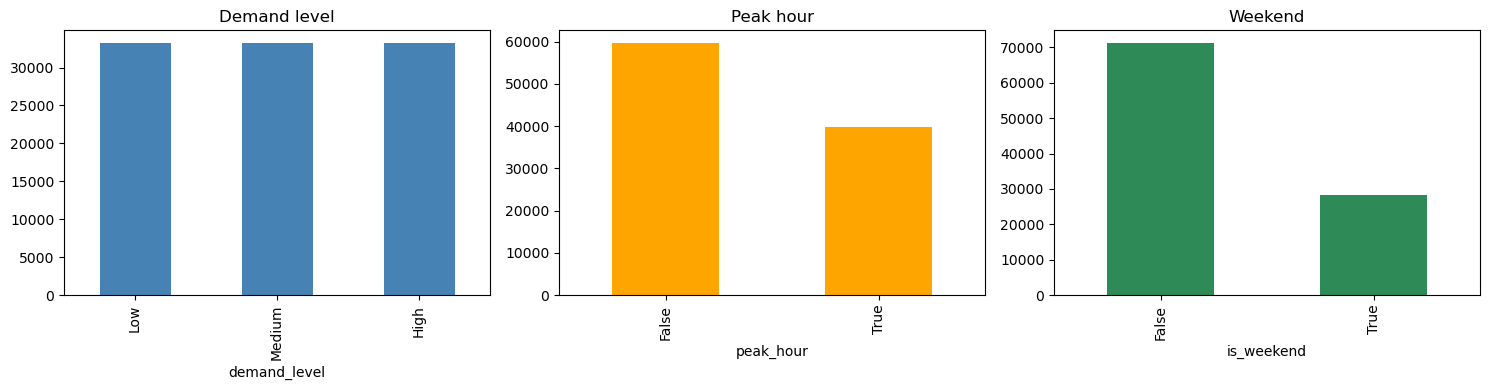

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["demand_level"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue", title="Demand level")
df["peak_hour"].value_counts().plot(kind="bar", ax=axes[1], color="orange", title="Peak hour")
df["is_weekend"].value_counts().plot(kind="bar", ax=axes[2], color="seagreen", title="Weekend")
plt.tight_layout()
plt.show()

**Conclusion:** the demand bands are balanced by construction (each ≈ 33 %). `peak_hour` (≈ 28 % peak) and `is_weekend` (≈ 28 % weekend) are moderately uneven, but that is natural – only 7 of 24 hours are peak and 2 of 7 days are weekend – so the data is **not seriously imbalanced** and no resampling (SMOTE, under-sampling) is needed.

### 4.7 Cleaned dataset summary

In [30]:
print("Final shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df.to_csv("EV_Charging_Station_Demand_Cleaned.csv", index=False)
df.head()

Final shape: (99629, 23)
Missing values: 0
Duplicates: 309


,timestamp,station_id,state,is_weekend,peak_hour,location_type,vehicle_type,charger_type,traffic_density,battery_capacity_kWh,...,station_load_percent,electricity_price_per_kWh,available_chargers,occupied_chargers,utilization_rate_percent,charging_demand,demand_level,hour,month,day_of_week
0,2024-05-16 08:16:00,STN_0253,Tamil Nadu,False,True,Shopping_Mall,Two_Wheeler,AC_Level_2,High,6.00,...,40.8,7.66,4.0,0.0,5.2,41.0,Medium,8,5,Thursday
1,2024-12-09 14:57:00,STN_0196,Delhi,False,False,Workplace,Car,AC_Level_2,High,54.23,...,8.0,6.65,6.0,1.0,3.0,60.8,Medium,14,12,Monday
2,2024-05-03 18:49:00,STN_0248,Tamil Nadu,False,True,Residential,Two_Wheeler,AC_Level_2,Medium,5.82,...,23.4,6.98,12.0,2.0,13.0,21.2,Low,18,5,Friday
3,2024-07-07 12:32:00,STN_0302,Maharashtra,True,False,Shopping_Mall,Car,AC_Level_2,Medium,62.93,...,29.0,7.13,5.0,1.0,22.9,58.5,Medium,12,7,Sunday
4,2024-08-16 08:02:00,STN_0001,West Bengal,False,True,Shopping_Mall,Car,DC_Fast,Very_High,50.08,...,29.4,6.76,2.0,3.0,61.3,98.7,High,8,8,Friday


## 5. Exploratory Data Analysis (EDA)

### 5.1 Univariate analysis

**Numeric columns – distributions**

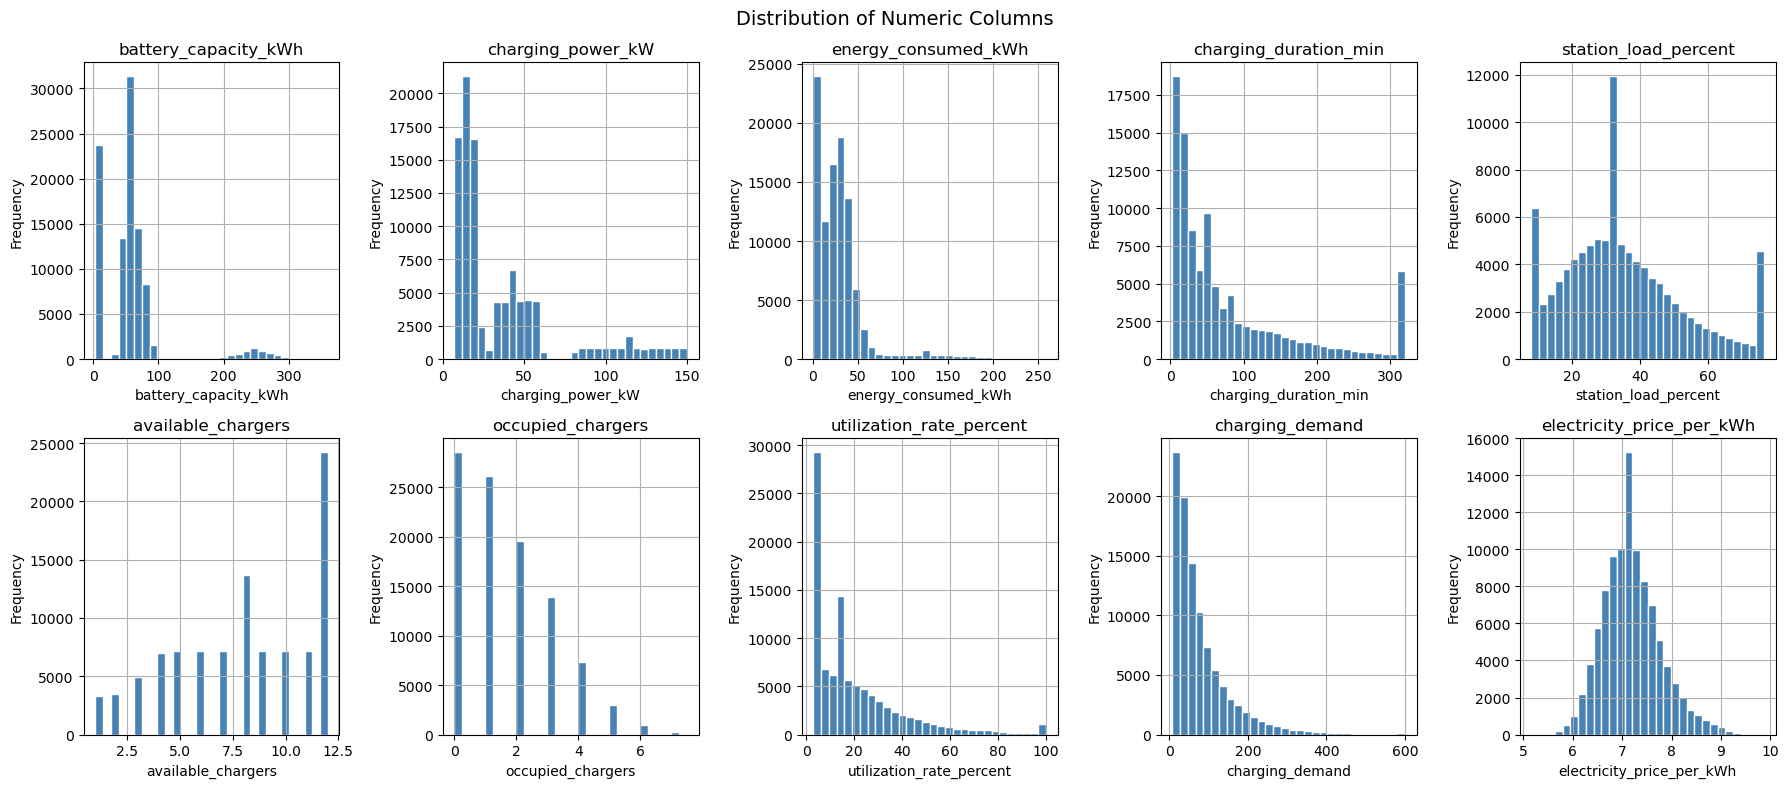

In [31]:
# df[num_cols].hist(bins=30, figsize=(18, 8), layout=(2, 5), color="steelblue", edgecolor="white")
# plt.suptitle("Distribution of numeric columns", fontsize=14)
# plt.tight_layout()
# plt.show()

axes = df[num_cols].hist(
    bins=30,
    figsize=(18, 8),
    layout=(2, 5),
    color="steelblue",
    edgecolor="white"
)

for ax in axes.flatten():
    ax.set_xlabel(ax.get_title(), fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)

plt.suptitle("Distribution of Numeric Columns", fontsize=14)
plt.tight_layout()
plt.show()

**Numeric columns – KDE (smooth version of the histograms)**

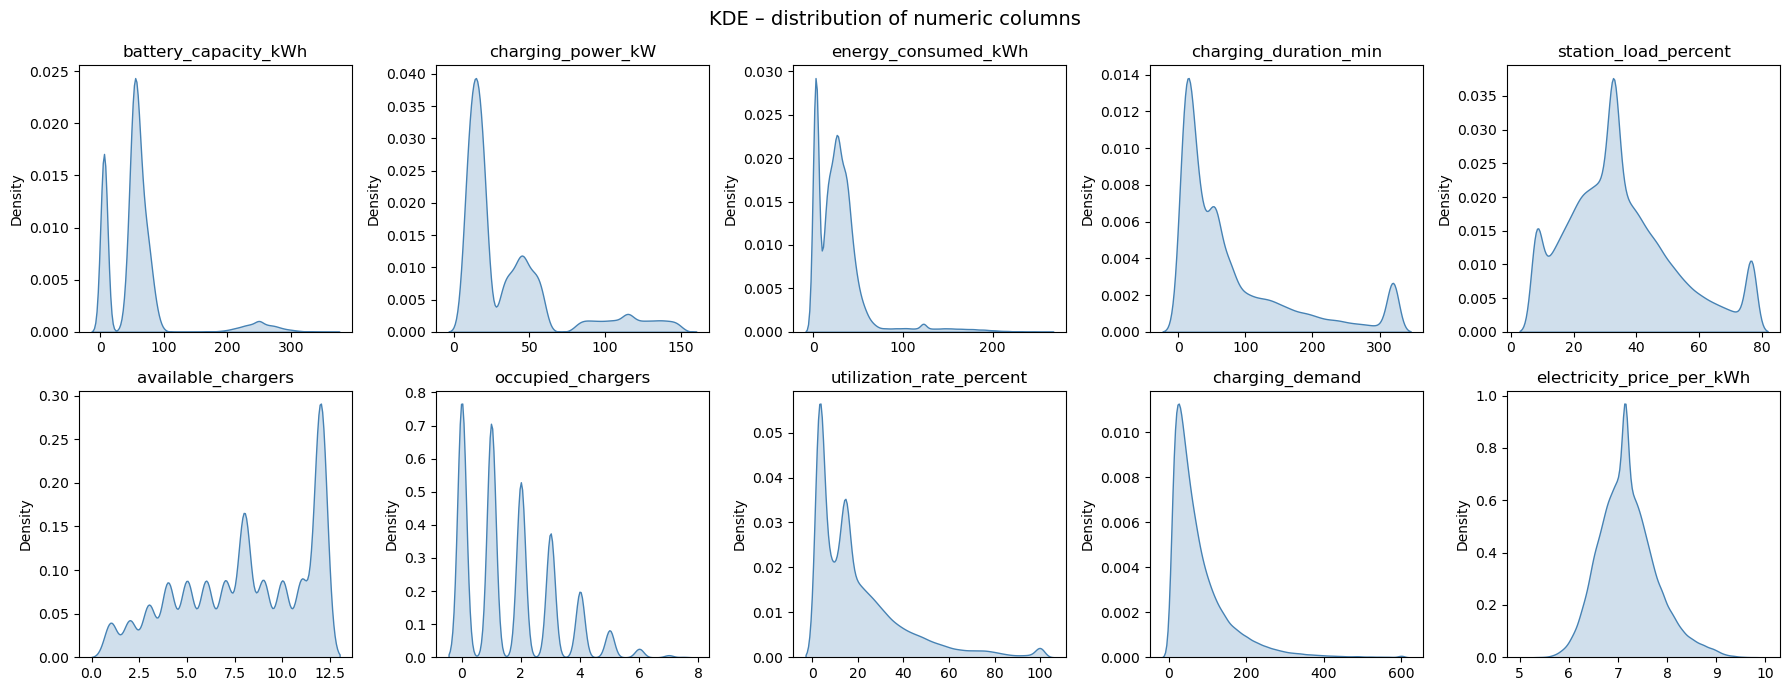

In [32]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.kdeplot(df[col], fill=True, color="steelblue", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("KDE – distribution of numeric columns", fontsize=14)
plt.tight_layout()
plt.show()

**Categorical columns – counts**

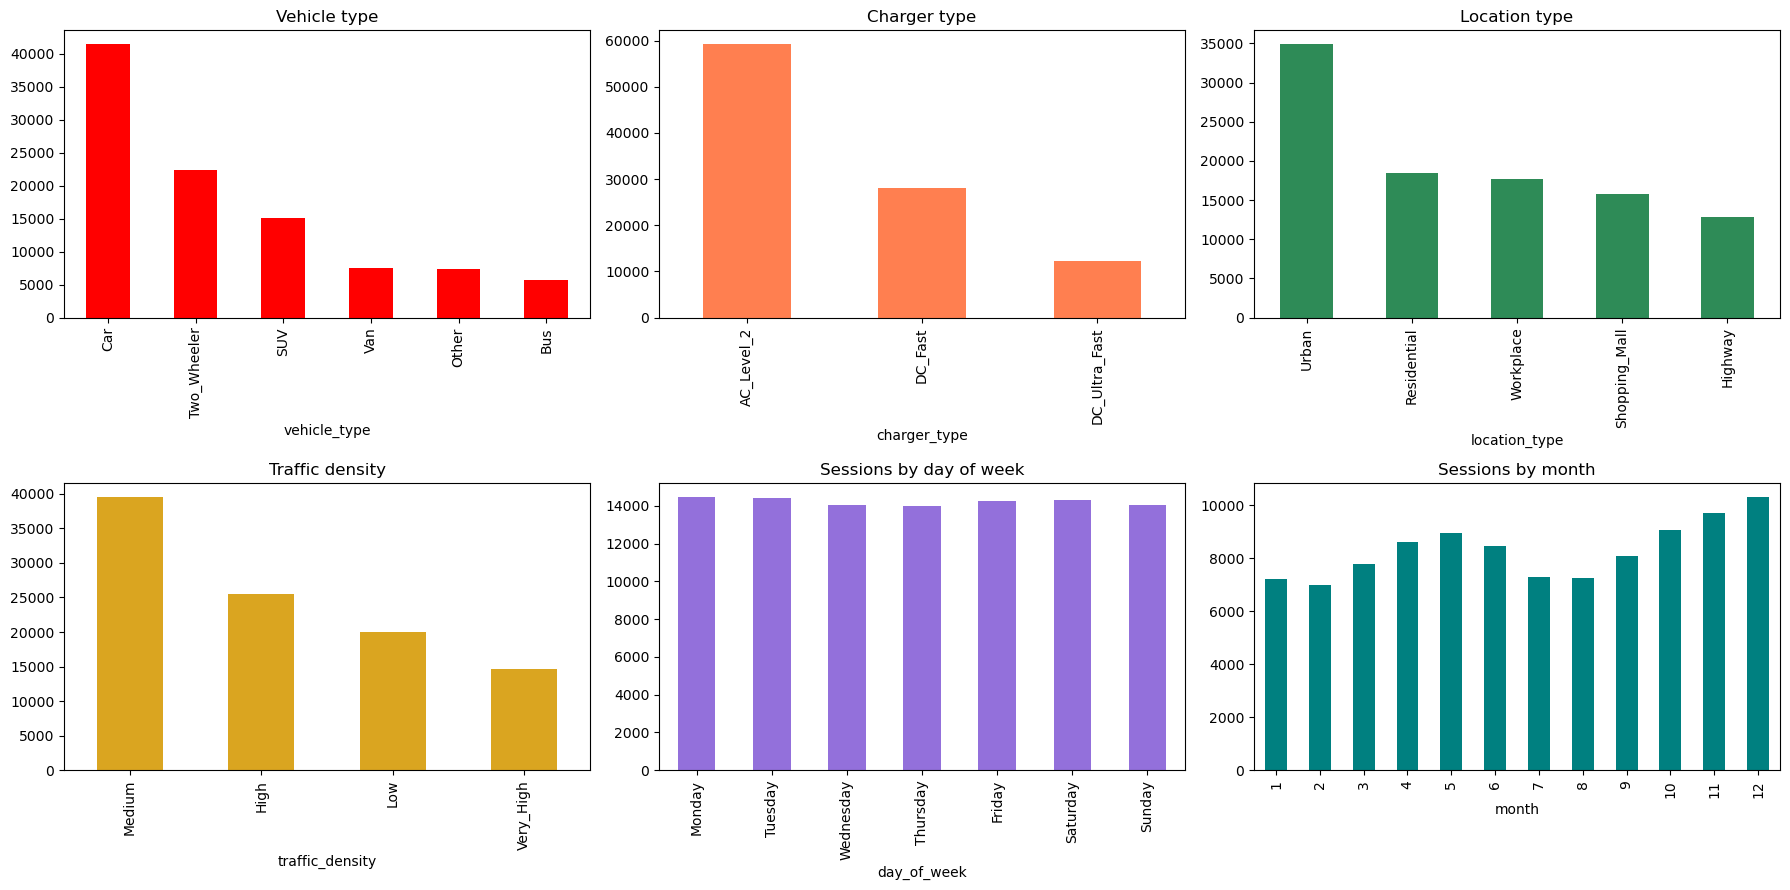

In [33]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
df["vehicle_type"].value_counts().plot(kind="bar", ax=axes[0, 0], color="red", title="Vehicle type")
df["charger_type"].value_counts().plot(kind="bar", ax=axes[0, 1], color="coral", title="Charger type")
df["location_type"].value_counts().plot(kind="bar", ax=axes[0, 2], color="seagreen", title="Location type")
df["traffic_density"].value_counts().plot(kind="bar", ax=axes[1, 0], color="goldenrod", title="Traffic density")
df["day_of_week"].value_counts().reindex(days).plot(kind="bar", ax=axes[1, 1], color="mediumpurple", title="Sessions by day of week")
df["month"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 2], color="teal", title="Sessions by month")
plt.tight_layout()
plt.show()

**Share of sessions – donut charts**

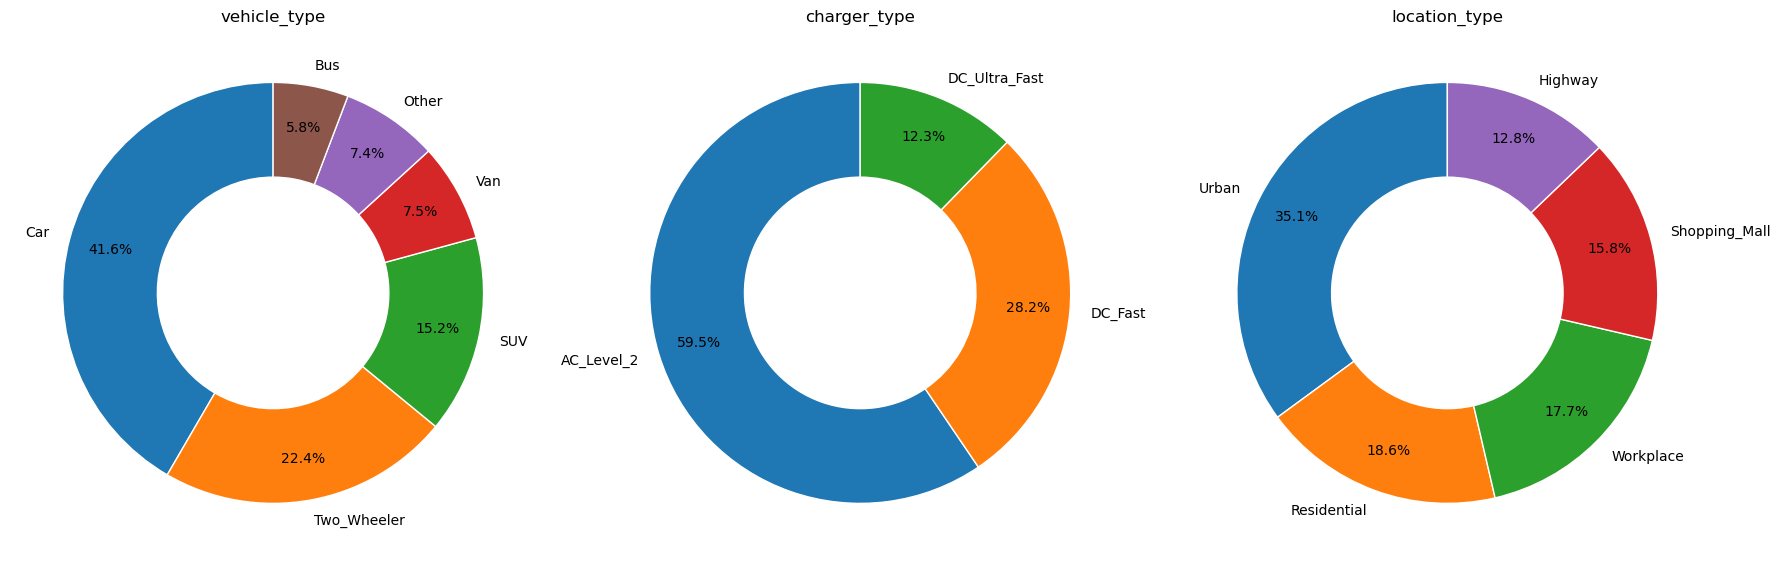

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, ["vehicle_type", "charger_type", "location_type"]):
    counts = df[col].value_counts()
    ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, pctdistance=0.8,
           wedgeprops=dict(width=0.45, edgecolor="white"))
    ax.set_title(col)
plt.tight_layout()
plt.show()

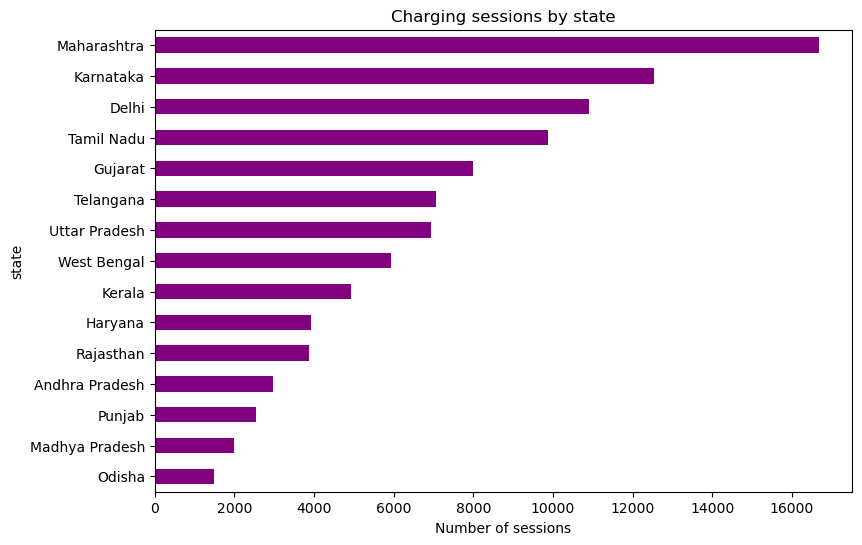

In [35]:
df["state"].value_counts().sort_values().plot(kind="barh", figsize=(9, 6), color="purple", title="Charging sessions by state")
plt.xlabel("Number of sessions")
plt.show()

**Sessions over time – line charts**

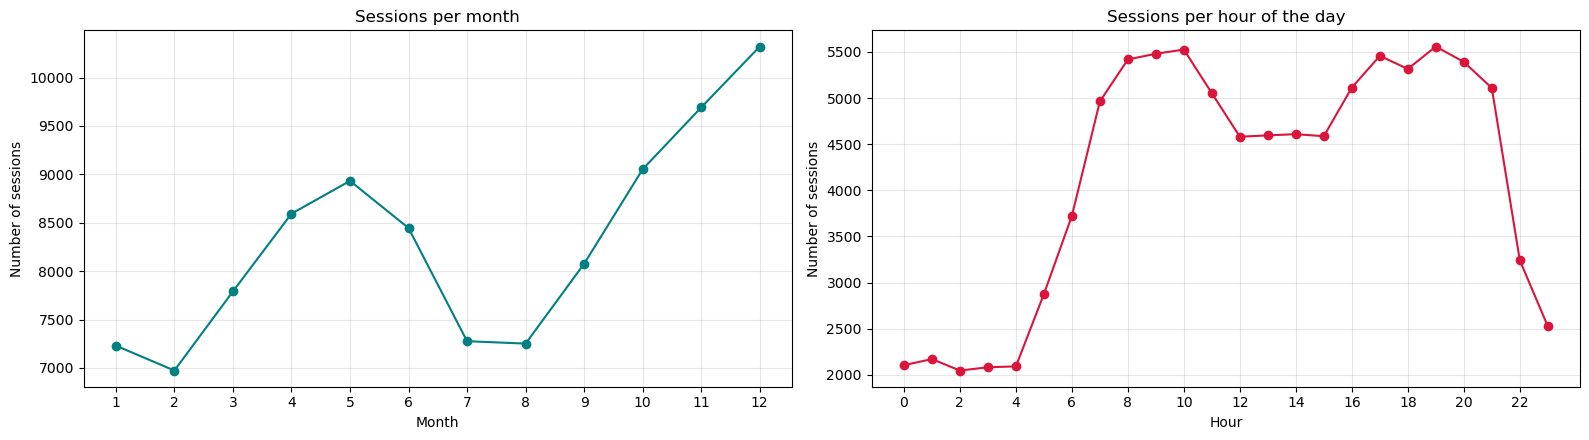

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
df["month"].value_counts().sort_index().plot(kind="line", marker="o", color="teal", ax=axes[0],
                                           title="Sessions per month")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Number of sessions"); axes[0].set_xticks(range(1, 13))
df["hour"].value_counts().sort_index().plot(kind="line", marker="o", color="crimson", ax=axes[1],
                                          title="Sessions per hour of the day")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("Number of sessions"); axes[1].set_xticks(range(0, 24, 2))
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.2 Bivariate analysis

**Categorical feature vs target (average `charging_demand`)**

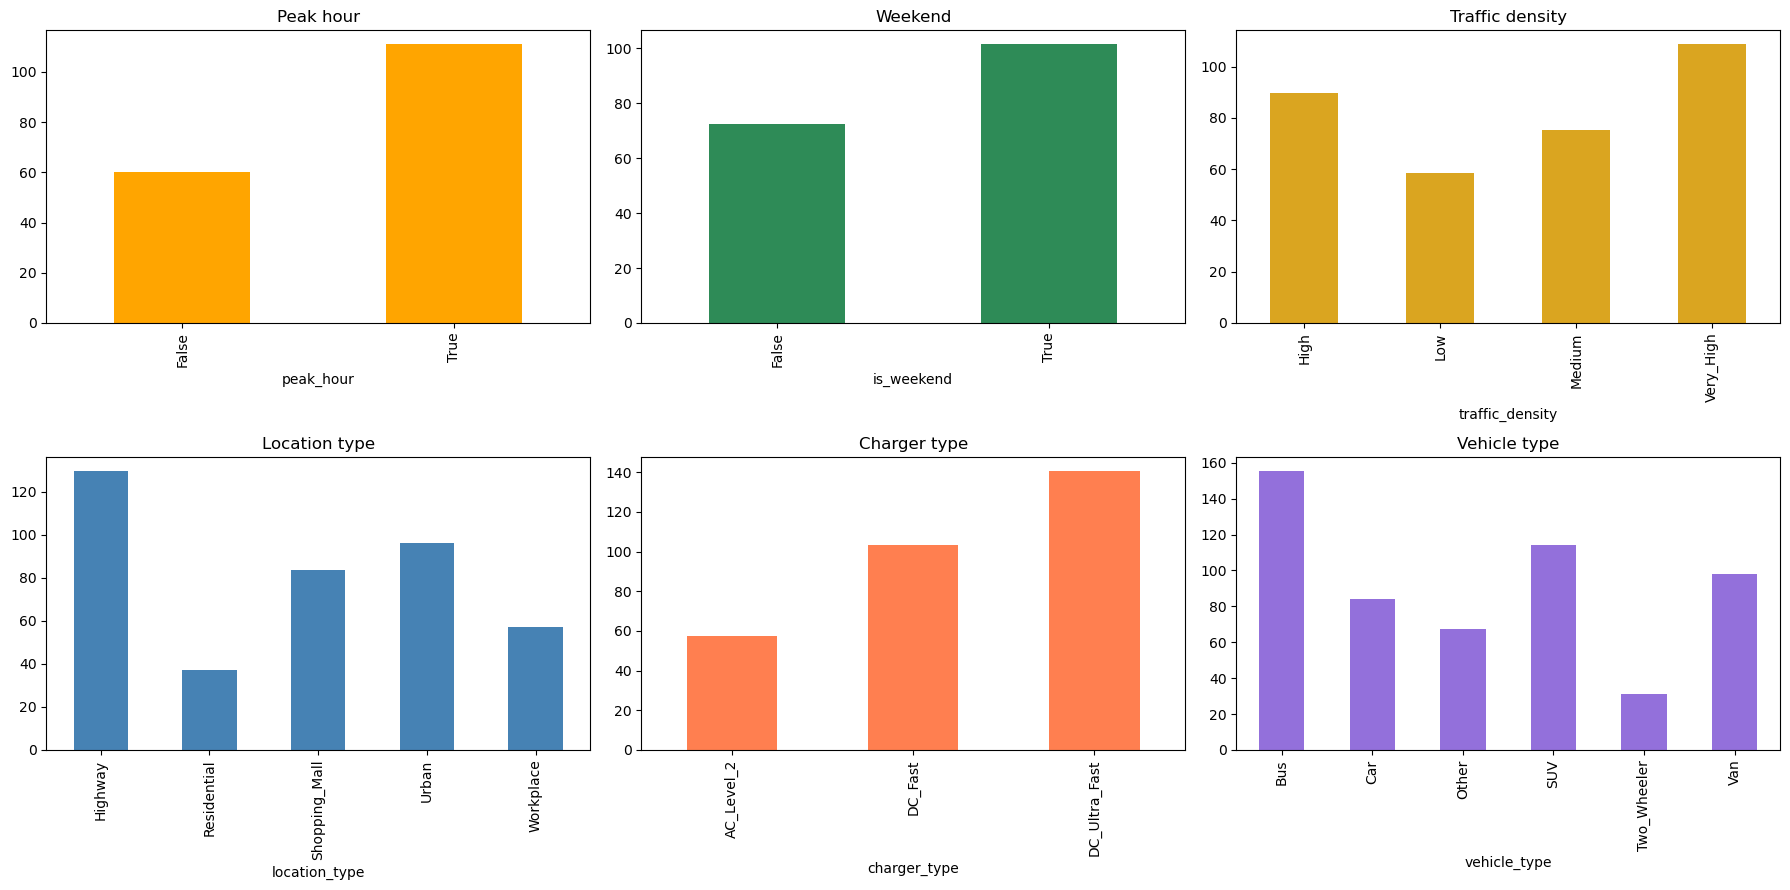

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
df.groupby("peak_hour")["charging_demand"].mean().plot(kind="bar", ax=axes[0, 0], color="orange", title="Peak hour")
df.groupby("is_weekend")["charging_demand"].mean().plot(kind="bar", ax=axes[0, 1], color="seagreen", title="Weekend")
df.groupby("traffic_density")["charging_demand"].mean().plot(kind="bar", ax=axes[0, 2], color="goldenrod", title="Traffic density")
df.groupby("location_type")["charging_demand"].mean().plot(kind="bar", ax=axes[1, 0], color="steelblue", title="Location type")
df.groupby("charger_type")["charging_demand"].mean().plot(kind="bar", ax=axes[1, 1], color="coral", title="Charger type")
df.groupby("vehicle_type")["charging_demand"].mean().plot(kind="bar", ax=axes[1, 2], color="mediumpurple", title="Vehicle type")
plt.tight_layout()
plt.show()

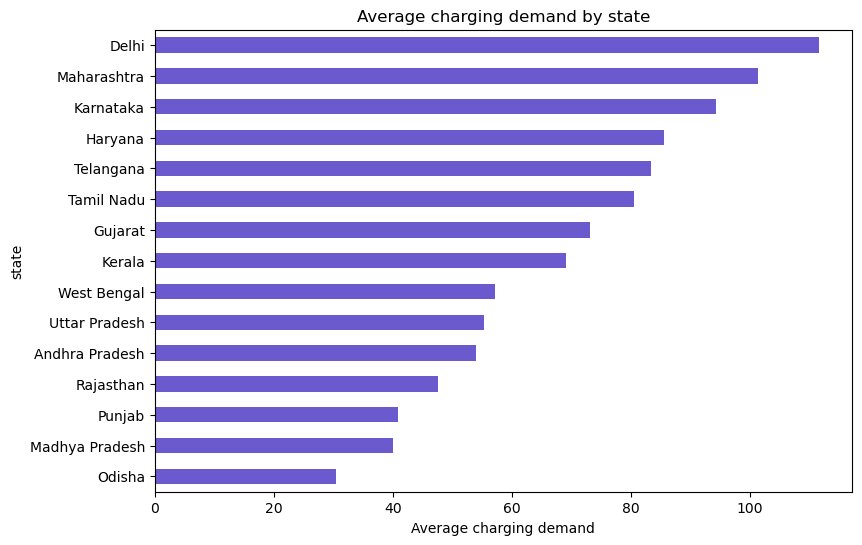

In [38]:
df.groupby("state")["charging_demand"].mean().sort_values().plot(kind="barh", figsize=(9, 6), color="slateblue",
                                                                 title="Average charging demand by state")
plt.xlabel("Average charging demand")
plt.show()

**State-wise demand – KDE, box plot and line views**

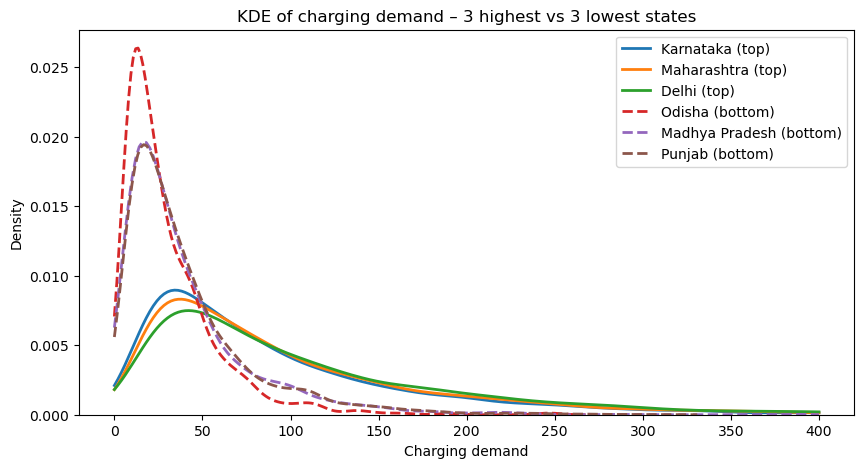

In [39]:
# KDE: do the highest-demand states really have a different demand curve than the lowest ones?
state_mean = df.groupby("state")["charging_demand"].mean().sort_values()
low3, high3 = list(state_mean.index[:3]), list(state_mean.index[-3:])
plt.figure(figsize=(10, 5))
for s in high3:
    sns.kdeplot(df.loc[df["state"] == s, "charging_demand"], label=f"{s} (top)", linewidth=2, clip=(0, 400))
for s in low3:
    sns.kdeplot(df.loc[df["state"] == s, "charging_demand"], label=f"{s} (bottom)", linewidth=2,
                linestyle="--", clip=(0, 400))
plt.title("KDE of charging demand – 3 highest vs 3 lowest states")
plt.xlabel("Charging demand"); plt.legend()
plt.show()

In [40]:
# Box plot: spread of demand in every state (sorted by median)
# order = df.groupby("state")["charging_demand"].median().sort_values(ascending=False).index
# plt.figure(figsize=(10, 7))
# sns.boxplot(data=df, y="state", x="charging_demand", order=order, color="slateblue", showfliers=False)
# plt.title("Charging demand spread by state")
# plt.xlabel("Charging demand")
# plt.show()

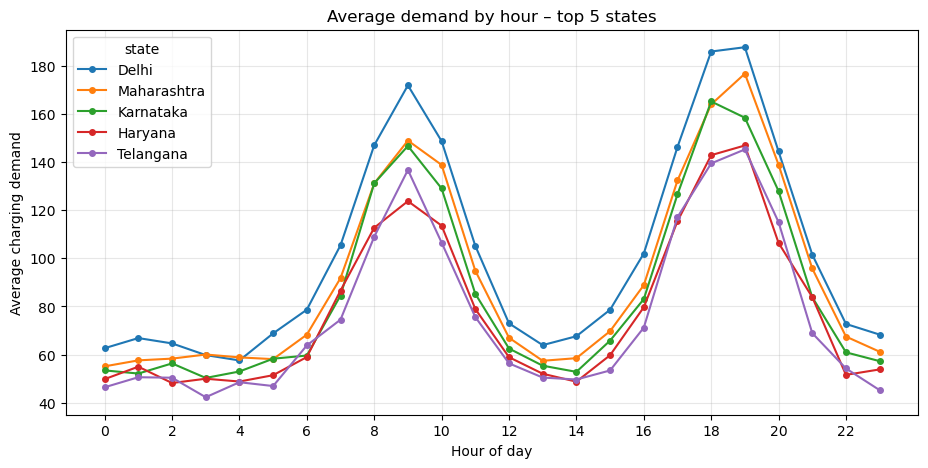

In [41]:
# Line chart: average demand through the day for the 5 highest-demand states
top5 = list(state_mean.index[-5:][::-1])
hourly = (df[df["state"].isin(top5)].groupby(["hour", "state"])["charging_demand"].mean()
          .unstack()[top5])
hourly.plot(figsize=(11, 5), marker="o", markersize=4, title="Average demand by hour – top 5 states")
plt.xlabel("Hour of day"); plt.ylabel("Average charging demand"); plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.show()

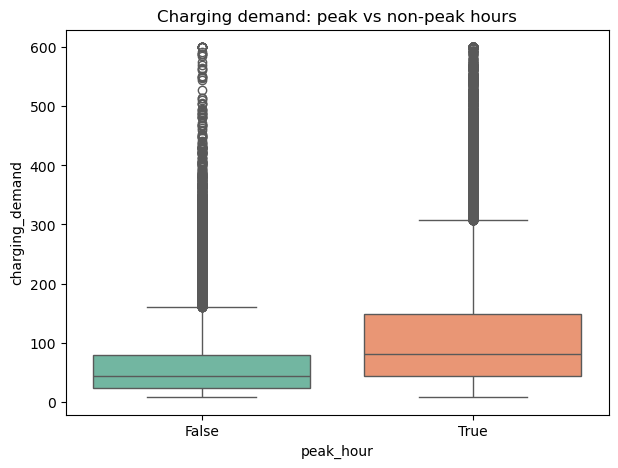

In [42]:
# Spread of demand in peak vs non-peak hours

plt.figure(figsize=(7, 5))
sns.boxplot(x="peak_hour", y="charging_demand", data=df, palette="Set2")
plt.title("Charging demand: peak vs non-peak hours")
plt.show()

**Demand patterns – KDE and line charts**

In [43]:
# fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# sns.kdeplot(data=df, x="charging_demand", hue="peak_hour", fill=True, common_norm=False,
#             palette={False: "steelblue", True: "orange"}, clip=(0, 400), ax=axes[0])
# axes[0].set_title("KDE – demand in peak vs non-peak hours")
# sns.kdeplot(data=df, x="charging_demand", hue="is_weekend", fill=True, common_norm=False,
#             palette={False: "steelblue", True: "seagreen"}, clip=(0, 400), ax=axes[1])
# axes[1].set_title("KDE – demand on weekdays vs weekends")
# plt.tight_layout()
# plt.show()

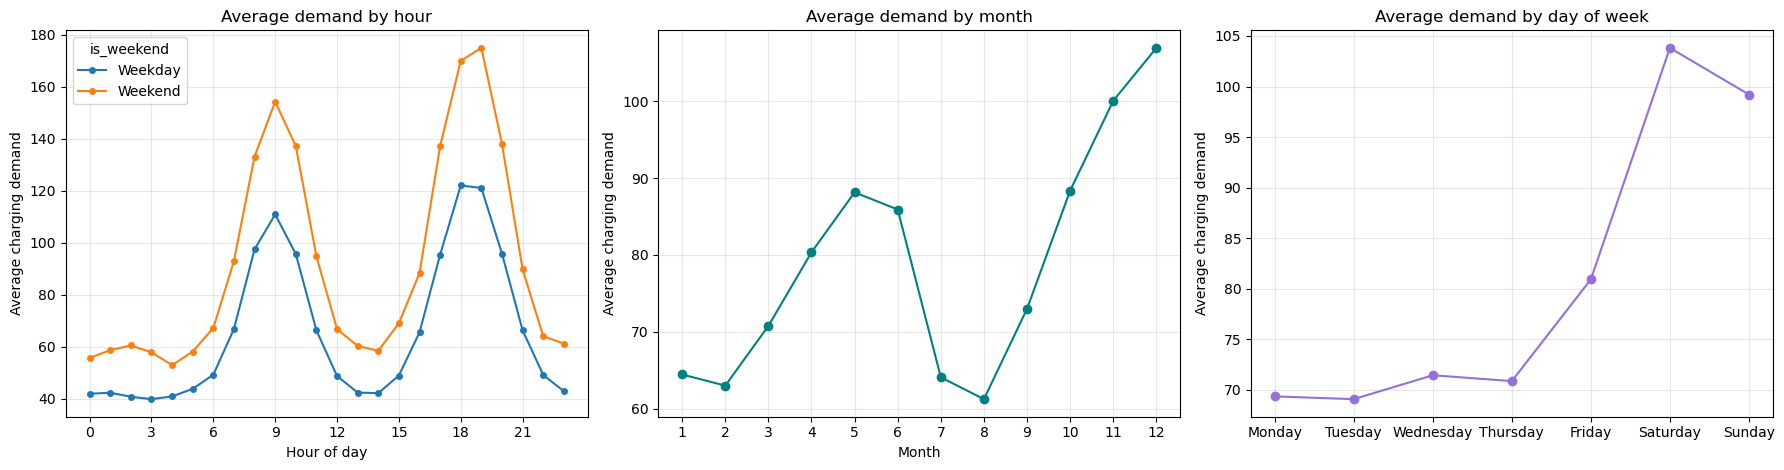

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# average demand by hour, weekday vs weekend
df.groupby(["hour", "is_weekend"])["charging_demand"].mean().unstack().rename(
    columns={False: "Weekday", True: "Weekend"}).plot(marker="o", markersize=4, ax=axes[0],
                                                      title="Average demand by hour")
axes[0].set_xlabel("Hour of day"); axes[0].set_xticks(range(0, 24, 3))

# average demand by month
df.groupby("month")["charging_demand"].mean().plot(marker="o", color="teal", ax=axes[1],
                                                 title="Average demand by month")
axes[1].set_xlabel("Month"); axes[1].set_xticks(range(1, 13))

# average demand by day of week
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df.groupby("day_of_week")["charging_demand"].mean().reindex(days).plot(marker="o", color="mediumpurple",
                                                                     ax=axes[2], title="Average demand by day of week")
axes[2].set_xlabel("")
for ax in axes:
    ax.set_ylabel("Average charging demand"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.3 Multivariant Analysis

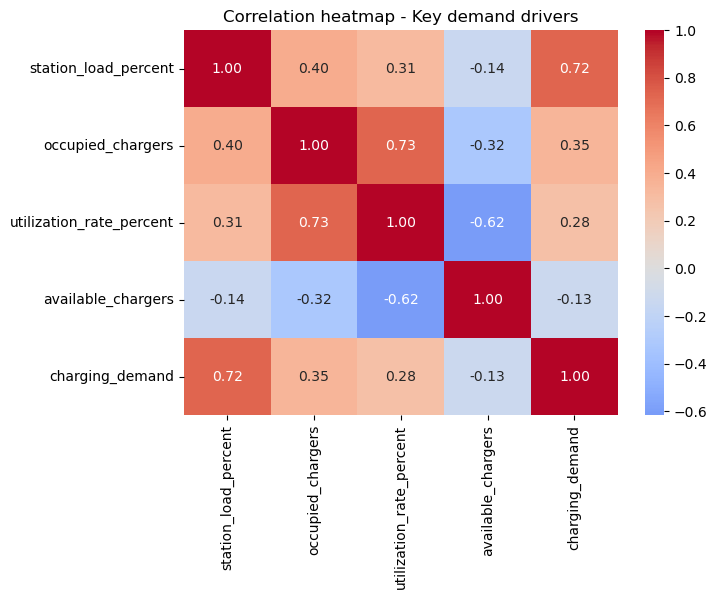

In [45]:
# Select only the most important columns for a focused heatmap
key_cols = [
    'station_load_percent',
    'occupied_chargers',
    'utilization_rate_percent',
    'available_chargers',
    'charging_demand'
]

plt.figure(figsize=(7, 5))
sns.heatmap(df[key_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap - Key demand drivers")
plt.show()

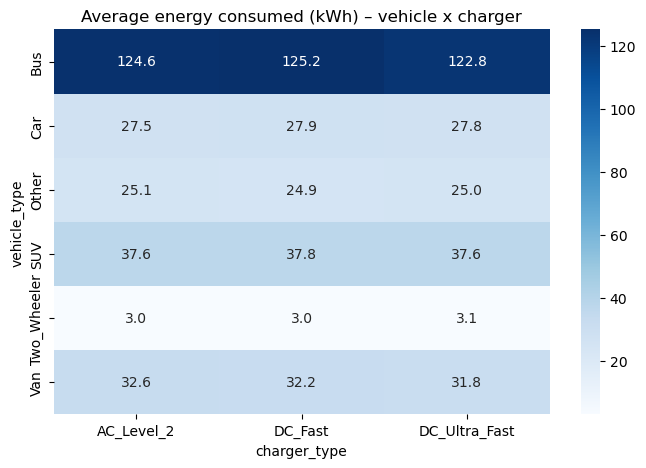

In [46]:
# Vehicle type x charger type -> average energy consumed
heat2 = pd.pivot_table(df, values="energy_consumed_kWh", index="vehicle_type", columns="charger_type", aggfunc="mean")
plt.figure(figsize=(8, 5))
sns.heatmap(heat2, cmap="Blues", annot=True, fmt=".1f")
plt.title("Average energy consumed (kWh) – vehicle x charger")
plt.show()

**Demand vs its drivers – scatter and heatmap**

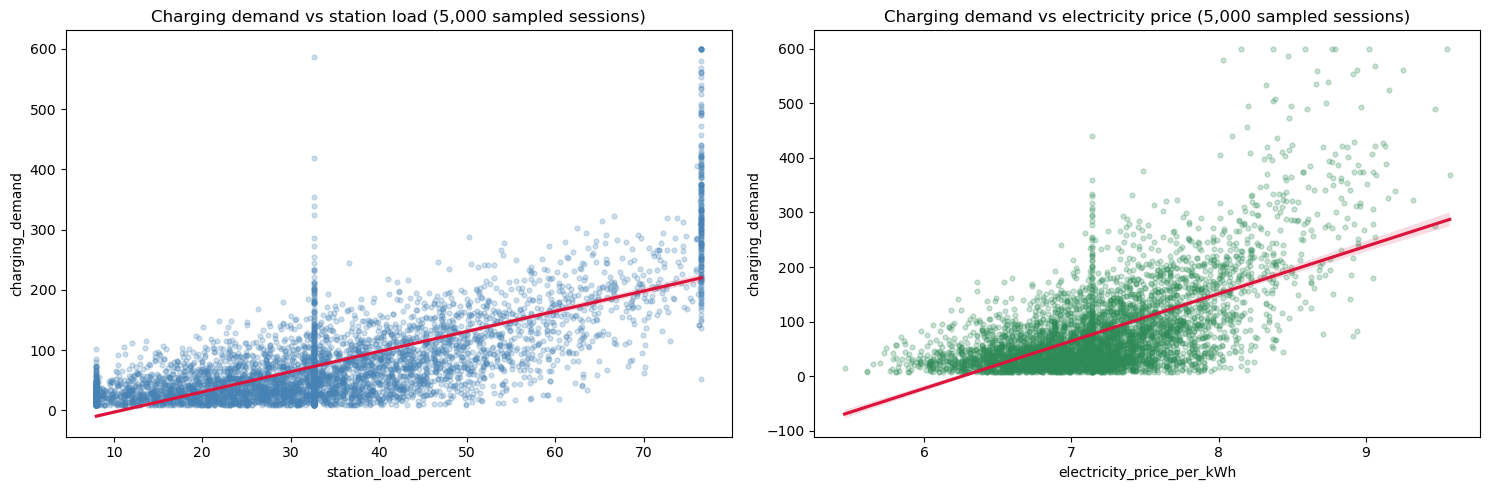

In [47]:
sample = df.sample(5000, random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(data=sample, x="station_load_percent", y="charging_demand", ax=axes[0],
            scatter_kws=dict(alpha=0.25, s=12, color="steelblue"), line_kws=dict(color="crimson"))
axes[0].set_title("Charging demand vs station load (5,000 sampled sessions)")
sns.regplot(data=sample, x="electricity_price_per_kWh", y="charging_demand", ax=axes[1],
            scatter_kws=dict(alpha=0.25, s=12, color="seagreen"), line_kws=dict(color="crimson"))
axes[1].set_title("Charging demand vs electricity price (5,000 sampled sessions)")
plt.tight_layout()
plt.show()

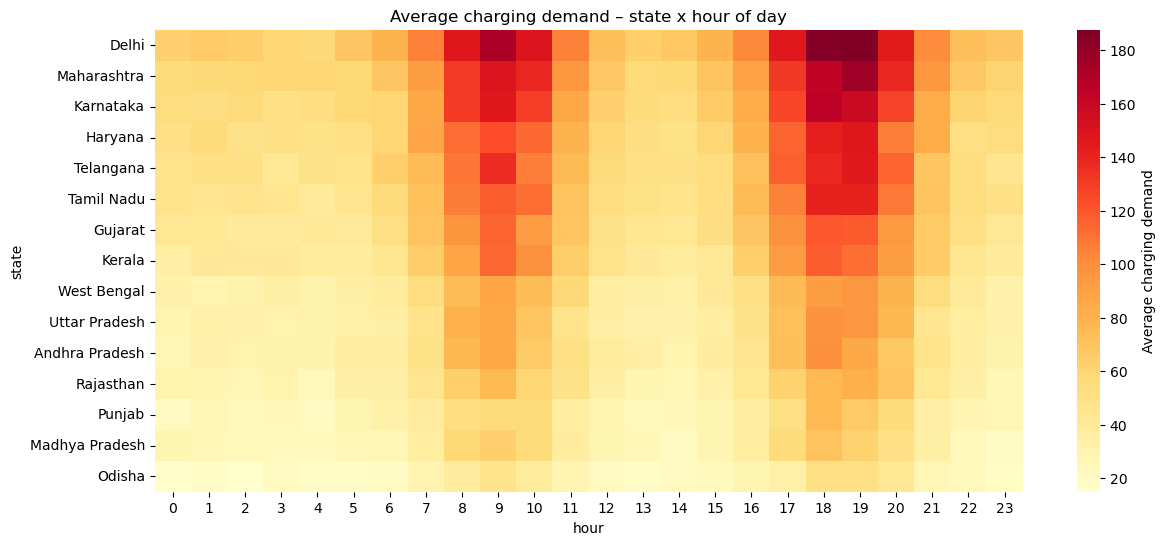

In [48]:
# State x hour of day -> average demand
heat3 = pd.pivot_table(df, values="charging_demand", index="state", columns="hour", aggfunc="mean")
heat3 = heat3.loc[df.groupby("state")["charging_demand"].mean().sort_values(ascending=False).index]
plt.figure(figsize=(14, 6))
sns.heatmap(heat3, cmap="YlOrRd", cbar_kws={"label": "Average charging demand"})
plt.title("Average charging demand – state x hour of day")
plt.show()

### 6. Pivot Tables

### 6.1 Average charging demand: state × location type

In [49]:
pt1 = pd.pivot_table(df, values="charging_demand", index="state", columns="location_type", aggfunc="mean", margins=True, margins_name="Overall")
pt1.round(1).style.background_gradient(cmap="YlGnBu")

location_type,Highway,Residential,Shopping_Mall,Urban,Workplace,Overall
state,,,,,,
Andhra Pradesh,86.400000,24.300000,56.300000,62.200000,38.700000,53.900000
Delhi,179.600000,50.900000,114.000000,132.800000,80.800000,111.600000
Gujarat,117.500000,33.300000,75.600000,86.800000,51.000000,73.200000
Haryana,134.200000,40.800000,90.800000,100.100000,63.800000,85.500000
Karnataka,151.600000,43.900000,97.900000,113.600000,66.300000,94.400000
Kerala,112.200000,32.500000,72.500000,81.900000,48.600000,69.200000
Madhya Pradesh,73.500000,18.300000,41.100000,46.100000,25.800000,40.100000
Maharashtra,162.200000,46.100000,105.300000,120.800000,73.200000,101.400000
Odisha,45.900000,13.400000,32.600000,38.100000,21.300000,30.500000


**Insight:** Highway (113.9) and Urban (112.4) locations have the highest average demand and Residential (103.1) the lowest. Residential is the lowest location type in *every* state. Delhi (112.5), Maharashtra (111.7) and Karnataka (111.2) are the highest states overall and Madhya Pradesh (104.6) the lowest – the gap between states (~8 points) is smaller than the gap between location types (~11 points).

## 7. Key Findings

**Data quality**
* 104,500 rows → 2,500 exact duplicates removed → 3,560 rows without a target dropped → **98,440 clean rows**, 0 missing values, 0 duplicates (23 columns including the helper columns `hour`, `month`, `demand_level`).
* Real outliers were kept where they are explained by the business (buses, slow AC charging) and only capped for `price_per_kwh`, `station_load_percent` and `occupied_chargers`.
* The data is not seriously imbalanced.

**What drives `charging_demand`**
1. **Peak hour is the strongest driver:** ≈ 136 vs ≈ 99 (+37 %). Demand at exactly 150 (the maximum) happens in ≈ 4.5 % of the rows, mostly in peak hours, so the target looks capped at 150.
2. **Station load** has the highest correlation with demand (0.64), followed by `occupied_chargers` / `utilization_rate_percent` (0.43) and `price_per_kwh` (0.32) – prices are also higher when stations are busier (correlation 0.40 with load).
3. **Traffic density** (Low ≈ 97 → Very_High ≈ 122) and **weekend** (≈ 117 vs ≈ 107) add a clear increase.
4. **Location type:** Highway and Urban are highest, Residential lowest. **State** matters less (≈ 105 to ≈ 113), with Delhi, Maharashtra and Karnataka on top.
5. **No effect:** vehicle type, charger type, battery capacity, charging power, energy consumed, duration, available chargers and month are all unrelated to demand (correlation ≈ 0, group averages ≈ 110).

**Notes for modelling**
* `battery_capacity_kwh` and `energy_consumed_kwh` are strongly correlated (0.80), and `available_chargers` / `utilization_rate_percent` are correlated (−0.60) – watch for multicollinearity in linear models.
* `charging_demand` is only mildly right-skewed (0.36) and needs no transformation.

In [50]:
print(df.shape, df["state"].nunique())
print(df["charging_demand"].describe())
print(df.groupby("state")["charging_demand"].agg(["mean", "count"]).round(1))

(99629, 23) 15
count    99629.000000
mean        80.623548
std         78.692973
min          8.000000
25%         28.800000
50%         55.200000
75%        103.800000
max        600.000000
Name: charging_demand, dtype: float64
                 mean  count
state                       
Andhra Pradesh   53.9   2962
Delhi           111.6  10904
Gujarat          73.2   7997
Haryana          85.5   3923
Karnataka        94.4  12540
Kerala           69.2   4924
Madhya Pradesh   40.1   1991
Maharashtra     101.4  16675
Odisha           30.5   1479
Punjab           41.0   2541
Rajasthan        47.6   3877
Tamil Nadu       80.5   9882
Telangana        83.4   7055
Uttar Pradesh    55.3   6941
West Bengal      57.1   5938


### Questions
- what is regression
- target variable is continuous or discreate value
- significant of heatmap
- what is heatmap
- within 2 weeks which changes you are done in your project
- when we use mean and median
- what is different between pie and donut chart